<a href="https://colab.research.google.com/github/mayayonathan/ds2002-fa26/blob/main/notebooks/07-visualization/2026-11-13%20%E2%80%94%20Visualization%20Challenge%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

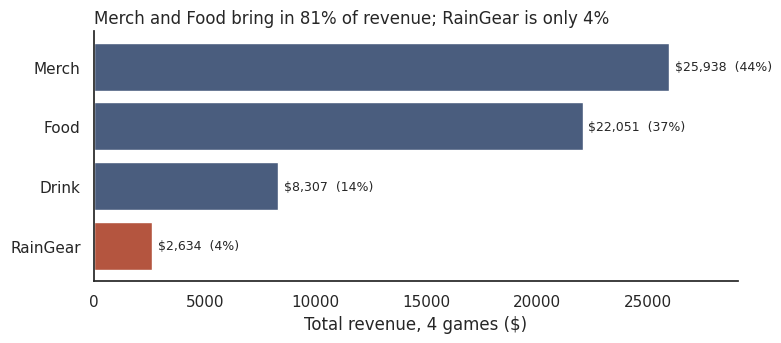

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [2]:
# Chart 1: revenue by category (sorted horizontal bar, axis from zero)
rev_cat = df.groupby('category')['revenue'].sum().sort_values()   # ascending -> largest bar on top
share = rev_cat / rev_cat.sum()
top2 = share[['Merch', 'Food']].sum()

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [RUST if c == 'RainGear' else BLUE for c in rev_cat.index]
ax.barh(rev_cat.index, rev_cat.values, color=colors)
ax.set_xlim(0, rev_cat.max() * 1.12)
for y, v in enumerate(rev_cat.values):
    ax.text(v + rev_cat.max() * 0.01, y, f'${v:,.0f}  ({v / rev_cat.sum():.0%})', va='center', fontsize=9)
finish(ax, f'Merch and Food bring in {top2:.0%} of revenue; RainGear is only {share["RainGear"]:.0%}',
       xlabel='Total revenue, 4 games ($)', ylabel='')
plt.show()
score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption:** Merch and Food carry about 81% of revenue, so they get the staffing and stock priority; RainGear (4%) is a small line that should be stocked only when rain is forecast.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

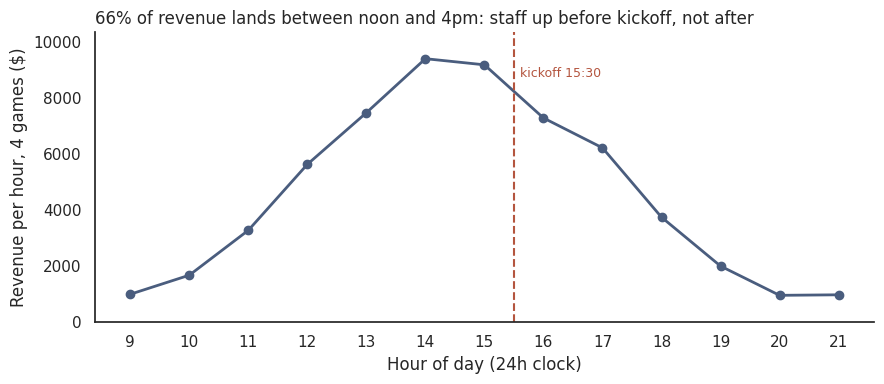

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [3]:
# Chart 2: revenue by hour, kickoff marked at 15.5
rev_hr = df.groupby('hour')['revenue'].sum()
window = rev_hr.loc[12:16].sum() / rev_hr.sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rev_hr.index, rev_hr.values, color=BLUE, marker='o', lw=2)
ax.axvline(15.5, color=RUST, ls='--', lw=1.5)
ax.text(15.6, rev_hr.max() * 0.97, 'kickoff 15:30', color=RUST, va='top', fontsize=9)
ax.set_ylim(0, rev_hr.max() * 1.1)
ax.set_xticks(rev_hr.index)
finish(ax, f'{window:.0%} of revenue lands between noon and 4pm: staff up before kickoff, not after',
       xlabel='Hour of day (24h clock)', ylabel='Revenue per hour, 4 games ($)')
plt.show()
score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption:** Revenue builds from noon, peaks at 2pm (about $9,400 across the four games), and is already falling by kickoff at 3:30pm, so full staffing should be in place by noon rather than at kickoff.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

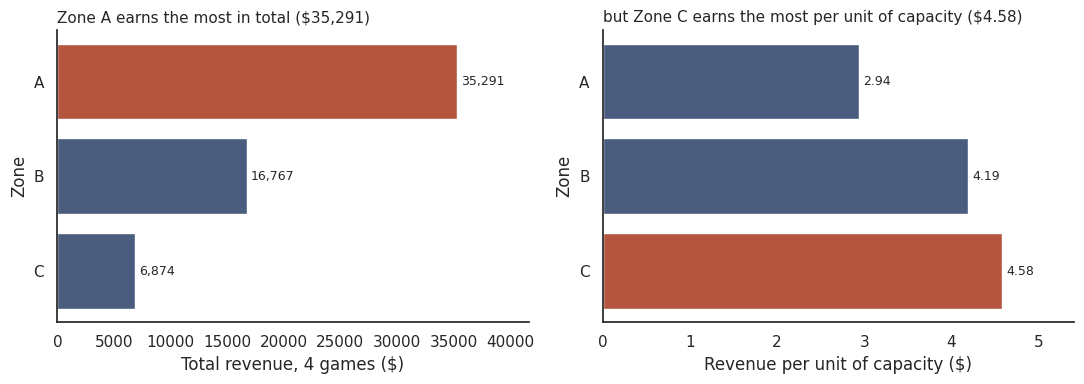

{'A': 35291.0, 'B': 16767.0, 'C': 6874.0} {'A': 2.94, 'B': 4.19, 'C': 4.58}
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [4]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
rev_zone = df.groupby('zone')['revenue'].sum()
per_cap = rev_zone / pd.Series(zone_capacity)
zones = list(zone_capacity)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, vals, hi, title, xl in [
    (axes[0], rev_zone, 'A', f'Zone A earns the most in total (${rev_zone["A"]:,.0f})', 'Total revenue, 4 games ($)'),
    (axes[1], per_cap, 'C', f'but Zone C earns the most per unit of capacity (${per_cap["C"]:.2f})', 'Revenue per unit of capacity ($)')]:
    v = vals.loc[zones]
    ax.barh(zones, v.values, color=[RUST if z == hi else BLUE for z in zones])
    ax.invert_yaxis()
    ax.set_xlim(0, v.max() * 1.18)
    for y, x in enumerate(v.values):
        ax.text(x + v.max() * 0.01, y, f'{x:,.2f}' if vals is per_cap else f'{x:,.0f}', va='center', fontsize=9)
    ax.set_title(title, loc='left', fontsize=11)
    ax.set_xlabel(xl); ax.set_ylabel('Zone')
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
fig.tight_layout()
plt.show()
print(rev_zone.round(0).to_dict(), per_cap.round(2).to_dict())
score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption, and which panel I would present:** Zone A brings in the most money in total (\$35,291) but Zone C earns the most per unit of capacity (\$4.58 vs \$2.94 for A). I would show the per-capacity panel to a manager deciding where space is being used best or where to add capacity, and the raw panel to someone planning staffing and stock volume, because that follows total sales.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

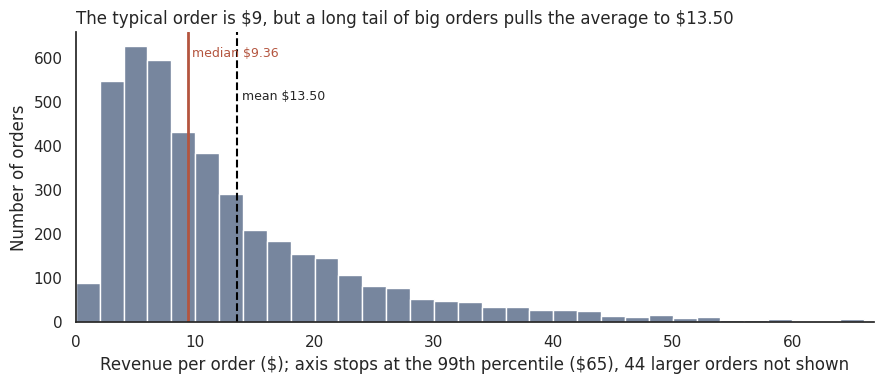

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6


6

In [5]:
# Chart 4: distribution of individual order revenue
med, mean, p99 = df['revenue'].median(), df['revenue'].mean(), df['revenue'].quantile(0.99)
n_above = int((df['revenue'] > p99).sum())

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(df['revenue'], bins=np.arange(0, p99 + 2, 2), color=BLUE, ax=ax)
ax.axvline(med, color=RUST, lw=2); ax.text(med + 0.4, ax.get_ylim()[1] * 0.95, f'median ${med:.2f}', color=RUST, va='top', fontsize=9)
ax.axvline(mean, color='black', ls='--', lw=1.5); ax.text(mean + 0.4, ax.get_ylim()[1] * 0.80, f'mean ${mean:.2f}', va='top', fontsize=9)
ax.set_xlim(0, p99 + 2)
finish(ax, f'The typical order is ${med:.0f}, but a long tail of big orders pulls the average to ${mean:.2f}',
       xlabel=f'Revenue per order ($); axis stops at the 99th percentile (${p99:.0f}), {n_above} larger orders not shown',
       ylabel='Number of orders')
plt.show()
score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)

**Caption:** Most orders are small (\$5 to \$17) and a few are very large, so planning around the average (\$13.50) would overstate what a typical customer spends; use the median (\$9.36) for a typical-order target and keep the big-ticket orders in mind for staffing the tills.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

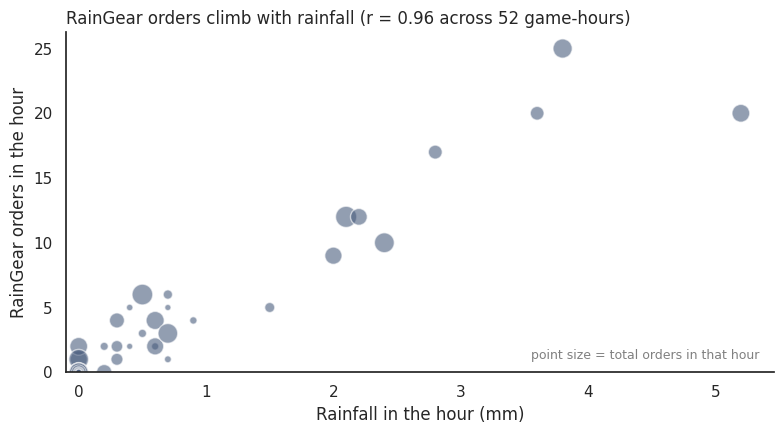

game-hours with 0 mm rain: 26 | with rain: 26
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 5/6


5

In [6]:
# Chart 5: does RainGear demand follow rainfall? One point = one game-hour
gh = (df.groupby(['game', 'hour'])
        .agg(rain_mm=('rain_mm', 'first'), orders=('category', 'size'),
             raingear=('category', lambda s: (s == 'RainGear').sum()))
        .reset_index())
r = gh['rain_mm'].corr(gh['raingear'])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(gh['rain_mm'], gh['raingear'], s=gh['orders'] * 1.2, color=BLUE, alpha=0.6, edgecolor='white')
ax.set_xlim(left=-0.1); ax.set_ylim(bottom=0)
finish(ax, f'RainGear orders climb with rainfall (r = {r:.2f} across {len(gh)} game-hours)',
       xlabel='Rainfall in the hour (mm)', ylabel='RainGear orders in the hour')
ax.text(0.98, 0.04, 'point size = total orders in that hour', transform=ax.transAxes, ha='right', fontsize=9, color='gray')
plt.show()
print('game-hours with 0 mm rain:', int((gh['rain_mm'] == 0).sum()), '| with rain:', int((gh['rain_mm'] > 0).sum()))
score(title=True, axes=True, chart=True, scale=True, readable=False, ink=True)   # dry-hour points overlap at 0 mm

**Caption:** RainGear sales are near zero in dry hours and rise steadily with rainfall (r = 0.96), so stock levels should follow the forecast for the game, not the season average.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
scores = {
    'chart 1 (category)': 6,
    'chart 2 (hour)': 6,
    'chart 3 (zone)': 6,
    'chart 4 (distribution)': 6,
    'chart 5 (your choice)': 5,   # point labels would help; size legend is only a text note
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your choice)      5/6  [ok]

average: 5.8/6


### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

**a)** Chart 3 made me reconsider. Zone C gets the most per unit (\$4.58 vs. \$2.94 for A), therefore the raw chart was mostly showing me which zone is largest, even though Zone A appears to be the obvious winner on raw revenue. Chart 4 also caught me off guard: due to a few very large orders, the average order (\$13.50) is significantly higher than the typical order (\$9.36).

**b)** When it comes to questions about volume, such as how much to stock, how many employees to schedule, or how much money a zone generates overall, the raw panel is the best option. When it comes to efficiency, such as which zone makes the best use of its area or where expanding capacity would be beneficial, the per-capacity panel is correct. When making an investment or space decision, I would show a management the per-capacity view; when organizing a game day, I would show them the raw view.